# 🧪 LAB: Implement an autoencoder with `PyTorch`

In this lab, you will implement and explore autoencoders using the MNIST dataset. The goal is to understand how autoencoders learn compressed representations of data, and how these representations compare with classical methods like PCA.

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


NAME(s) = ""

## 1. Theoretical Background Reflection (10 points)

Read *Michelucci (2022)*: [An Introduction to Autoencoders](https://arxiv.org/abs/2201.03898) — focus on the following sections:  
- 1. Introduction
- 2.1, 2.2, and 2.3
- Skim Section 3 on applications  

Then answer briefly:

1. What is the main idea behind an autoencoder?  
2. What is the role of the bottleneck layer?  
3. Discuss, in your own words, the applications of autoencoders mentioned in the paper.  
4. What differences would you expect between an autoencoder’s representation and that of PCA if applied as a dimensionality reduction technique?


1. The main idea behind an autoencoder is to extract the essential information to be able to reconstruct the input observations well enough. The goal of an autoencoder is to find a latent representation (the essential information we extract) which can be used later for feature extraction to then be used in classification and clustering or simply understanding the essential features of a dataset.
   
2. The goal is to create a latent representation so we do not reconstruct the output perfectly. A bottleneck layer supports this by making latent feature's dimensionality far lower than the input's.
   
3. Some applications of autoencoders are dimensionality reduction by producing q real numbers and it's more computationally efficient than normal PCA, which makes it good for large datasets. Another application is classification with latent features. Autoencoders are far quicker than algorithms like kNN with a loss of accuracy under 10% usually. One more application is anomaly detection where the highest reconstruction error will be an anomaly because the autoencoder hasn't been trained on it yet. Another applation of autoencoders would be denoising the input observations so that the output has far less noise.
   
4. One diffrence would be the computational cost and speed, autoencoders can be more flexible and consider non-linear transformation of features. And PCA provides a linear transformation of features.

## 2. Prepare the Data (10 points)

Given the below dataset:

- Normalize **each** image (i.e., separately) so its values are between 0 and 1. Remember our first-week discussions of fixed and fitted transformations.
- Visualize a few random digits to confirm everything worked as expected.
- Split the dataset into fitting, tuning and reporting sets (70%, 15%, 15%).
- Wrap each data splitting as `DataLoader` object with a batch size of 128. Call them `fitting_loader`, `tuning_loader` and `reporting_loader`, respectively.

In [54]:
from sklearn.datasets import fetch_openml
mnist = fetch_openml("mnist_784", version=1, as_frame=False, n_retries=5, delay=2)
X, y = mnist.data, mnist.target.astype(int)

In [55]:
X = X.astype("float32")

for i in range(len(X)):
    img = X[i]
    X[i] = (img - img.min())/(img.max() - img.min())

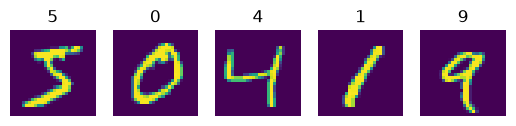

In [56]:
import matplotlib.pyplot as plt

for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(X[i].reshape(28, 28))
    plt.title(y[i])
    plt.axis("off")
plt.show()

In [57]:
from sklearn.model_selection import train_test_split

X_fit, X_test, y_fit, y_test = train_test_split(X, y, test_size=0.3, random_state=1234)
X_tune, X_report, y_tune, y_report = train_test_split(X_test, y_test, test_size=0.5, random_state=1234)

In [58]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# Fitting set
fitting_data = TensorDataset(torch.tensor(X_fit), torch.tensor(y_fit))
fitting_loader = DataLoader(fitting_data, batch_size=128, shuffle=True)

# Tuning set
tuning_data = TensorDataset(torch.tensor(X_tune), torch.tensor(y_tune))
tuning_loader = DataLoader(tuning_data, batch_size=128)

# Reporting set
reporting_data = TensorDataset(torch.tensor(X_report), torch.tensor(y_report))
reporting_loader = DataLoader(reporting_data, batch_size=128)

## 3. Autoencoder

In this section, you will build and train an **autoencoder** to reconstruct the provided data.

Your model will include three layers in both the encoder and decoder:

- **Encoder:** 784 → 128 → 64 → 2. This last layer here is the **bottleneck**.
- **Decoder:** 2 → 64 → 128 → 784  

### 3.1 Implementation (30 points)

Follow the skeleton provided below and fill in the missing parts (`#TODO`). 

Follow these restrictions:

- Each **hidden** layer should include a linear transformation, ReLU activation function, dropout with `p=0.2` and batch normalization steps. Determine the appropriate order for these components based on what we discussed in class. The bottleneck layer is the exception; see next point.
- For the bottleneck, use only a linear transformation, i.e., no activation, batch normalization, or dropout.
- The output layer should have a sigmoid activation function.

In [59]:
import torch.nn as nn

class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        
        # ENCODING PART: 784 -> 128 -> 64 -> 2
        encoder_list = [
            # Hidden layer 1
            nn.Linear(784, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            # Hidden layer 2
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            # Bottleneck: linear only
            nn.Linear(64, 2)
        ]
        # TODO: Replace the None value below with the module that stores the layers in 'encoder_list' for manual iteration in the forward pass
        # Hint: we have covered this module in class
        self.encoder_list = nn.ModuleList(encoder_list)
        
        # DECODING PART: 2 -> 64 -> 128 -> 784
        decoder_list = [
            # Hidden layer 1
            nn.Linear(2, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            # Hidden layer 2
            nn.Linear(64, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            # Output layer
            nn.Linear(128, 784),
            nn.Sigmoid()
        ]
        # TODO: Replace the None value below with the module that stores the layers in 'decoder_list' for manual iteration in the forward pass
        # Hint: we have covered this module in class
        self.decoder_list = nn.ModuleList(decoder_list)
        
    def forward(self, X):
        # TODO: Replace the None value below for that after applying X -> encoder -> decoder
        # Hint: You will probably need to iterate through the encoder_list and decoder_list
        for layer in self.encoder_list:
            X = layer(X)
        for layer in self.decoder_list:
            X = layer(X)
        output = X
        return output

### 3.2 Training (15 points)

Follow the skeleton provided below and fill in the missing parts to train your model (`#TODO`). As you can see, training includes EarlyStopping, which I give you already for your convenience :-). After you have filled these missing parts, uncomment the provided piece of code with the function for training (`train_autoencoder`) your model and execute it.

But, **BEFORE** that, discuss with your mates and provide elaborated answers to the following:

- Why do you think the output layer of the autoencoder above uses a Sigmoid activation?
- Based on this, which cost function is most appropriate for this task? Justify your choice.

Why does the output layer use a Sigmoid activation?

An autoencoder tries to rebuild its input, so the output should be in the same range as the input. Our MNIST pixel values are scaled between 0 and 1. The sigmoid takes any number and squeezes it into the range 0 to 1, so every output value is a valid pixel value. Without the sigmoid, the last linear layer could output numbers like -3 or 5, which don’t make sense as pixels. Since the outputs are between 0 and 1, we can also think of each one as a probability, meaning how likely it is that the pixel is “on” (white) or “off” (black). This fits MNIST well, because most pixels are close to either black or white.

Which cost function is most appropriate? Justify your choice.

We think Binary Cross-Entropy (BCELoss) is the best choice. Because the sigmoid gives us a probability for each pixel, rebuilding the image is like making 784 small yes/no predictions, one per pixel. BCE is the standard loss for this kind of prediction. BCE also works well together with the sigmoid during training. When the model is very wrong about a pixel, BCE still gives a strong gradient, so the model keeps learning. Mean Squared Error (MSE) can give very small gradients when the sigmoid is close to 0 or 1, which slows learning down. BCE also needs its inputs to be between 0 and 1, and the sigmoid guarantees that. MSE would still work, but BCE is the better match for a sigmoid output and pixel values between 0 and 1.

Once you have discussed and agreed on the reasoning above, proceed to complete the skeleton (`#TODO`) and train the model.


In [60]:
# TODO: Replace None to instantiate the autoencoder
model = Autoencoder()

# TODO: Replace None with the appropriate Loss function from 'torch.nn'
# Hint: we are reconstructing continuous pixel values in [0,1]
criterion = torch.nn.BCELoss()

# TODO: Replace None with Adam optimizer. 
# Use learning rate of 0.001 and an L2 regularization via weight_decay of 1e-5
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)

In [61]:
class EarlyStopping:
    def __init__(self, patience=10, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False
        self.best_model_state = None

    def __call__(self, tuning_loss, model):
        if self.best_loss is None or tuning_loss < self.best_loss - self.min_delta:
            self.best_loss = tuning_loss
            self.counter = 0
            self.best_model_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True

    def restore_best_weights(self, model):
        if self.best_model_state is not None:
            model.load_state_dict(self.best_model_state)


def train_autoencoder(model, fitting_loader, tuning_loader, n_epochs=100, patience=5):
    # Initialize the early stopping object
    early_stopping = EarlyStopping(patience=patience)
    history = {"fitting": [], "tuning": []}

    for epoch in range(n_epochs):
        model.train()
        fitting_cost = 0.0

        for X_batch, _ in fitting_loader:
            # --- Implement the standard training steps ---
            
            outputs = model(X_batch)  # TODO: Forward pass for this batch
            cost = criterion(outputs, X_batch)     # TODO: Compute the cost for this batch
            
            cost.backward()  # TODO: Backward pass (compute gradients)
            optimizer.step()  # TODO: Update model parameters
            optimizer.zero_grad()  
    
            fitting_cost += cost.item() * X_batch.size(0)

        fitting_cost /= len(fitting_loader.dataset)

        # --- Tuning phase ---
        model.eval()
        tuning_cost = 0.0
        with torch.no_grad():
            for X_batch, _ in tuning_loader:
                outputs = model(X_batch)  # TODO: Forward pass for tuning data
                cost = criterion(outputs, X_batch)   # TODO: Compute the tuning cost
                tuning_cost += cost.item() * X_batch.size(0)

        tuning_cost /= len(tuning_loader.dataset)

        # --- Save metrics ---
        history["fitting"].append(fitting_cost)
        history["tuning"].append(tuning_cost)

        print(f"Epoch [{epoch+1}/{n_epochs}]  Fitting Cost: {fitting_cost:.5f}  Tuning Cost: {tuning_cost:.5f}")

        # --- Early stopping check ---
        early_stopping(tuning_cost, model)
        if early_stopping.early_stop:
            print(f"Stopping early at epoch {epoch+1}")
            early_stopping.restore_best_weights(model)
            return model, history

    return model, history


Once the missing parts have been filled, uncomment the piece of code below and execute it to train your model (it may take a bit to complete the training, which is totally normal).

In [62]:
model, history = train_autoencoder(model, fitting_loader, tuning_loader, n_epochs=50, patience=5)

Epoch [1/50]  Fitting Cost: 0.25936  Tuning Cost: 0.21228
Epoch [2/50]  Fitting Cost: 0.21477  Tuning Cost: 0.20474
Epoch [3/50]  Fitting Cost: 0.21031  Tuning Cost: 0.20179
Epoch [4/50]  Fitting Cost: 0.20800  Tuning Cost: 0.19948
Epoch [5/50]  Fitting Cost: 0.20612  Tuning Cost: 0.19794
Epoch [6/50]  Fitting Cost: 0.20500  Tuning Cost: 0.19673
Epoch [7/50]  Fitting Cost: 0.20410  Tuning Cost: 0.19555
Epoch [8/50]  Fitting Cost: 0.20347  Tuning Cost: 0.19437
Epoch [9/50]  Fitting Cost: 0.20275  Tuning Cost: 0.19362
Epoch [10/50]  Fitting Cost: 0.20218  Tuning Cost: 0.19304
Epoch [11/50]  Fitting Cost: 0.20173  Tuning Cost: 0.19244
Epoch [12/50]  Fitting Cost: 0.20138  Tuning Cost: 0.19261
Epoch [13/50]  Fitting Cost: 0.20110  Tuning Cost: 0.19160
Epoch [14/50]  Fitting Cost: 0.20068  Tuning Cost: 0.19091
Epoch [15/50]  Fitting Cost: 0.20053  Tuning Cost: 0.19077
Epoch [16/50]  Fitting Cost: 0.20038  Tuning Cost: 0.18979
Epoch [17/50]  Fitting Cost: 0.19995  Tuning Cost: 0.19034
Epoch 

In [63]:
# USE AS MANY CELLS AS NEEDED FOR THE REST OF THE CODE

### 3.3 Reconstruct (5 points)

Once you have trained the model: 

1. Visualize several reconstructed digits from the reporting set.  
2. Compare them with the corresponding original input digits. Was the reconstruction good? 

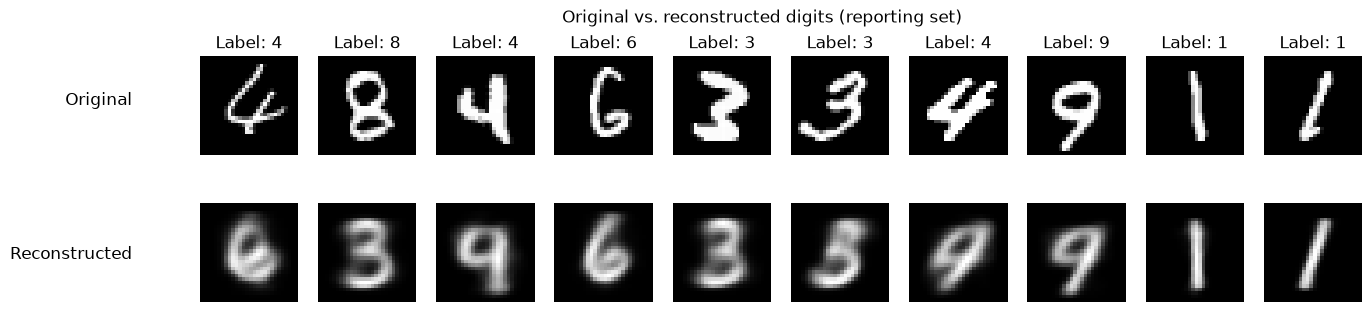

In [64]:
import matplotlib.pyplot as plt

model.eval()  # turn off dropout and use the stored batch norm statistics

# Take one batch from the reporting set
X_batch, y_batch = next(iter(reporting_loader))

with torch.no_grad():
    reconstructed = model(X_batch)

n = 10  # number of digits to show
fig, axes = plt.subplots(2, n, figsize=(15, 3.5))

for i in range(n):
    # Top row: original digits
    axes[0, i].imshow(X_batch[i].view(28, 28), cmap="gray")
    axes[0, i].set_title(f"Label: {y_batch[i].item()}")
    axes[0, i].axis("off")

    # Bottom row: reconstructed digits
    axes[1, i].imshow(reconstructed[i].view(28, 28), cmap="gray")
    axes[1, i].axis("off")

fig.text(0.08, 0.72, "Original", ha="right", va="center", fontsize=12)
fig.text(0.08, 0.28, "Reconstructed", ha="right", va="center", fontsize=12)
plt.suptitle("Original vs. reconstructed digits (reporting set)")
plt.show()

The reconstruction is only partly good. About half of the digits are reconstructed correctly: the 6, the first 3, the 9 and both 1s are clearly recognizable. The 1s are reconstructed best, because they have a very simple shape, and the model even keeps the slant of the second 1. However, all reconstructions are blurry and lose fine details like sharp edges and the exact thickness of the strokes.

Several digits are reconstructed as a different, similar-looking digit. The 8 becomes a 3, which makes sense because a 3 looks like an 8 with the left side missing. The second 3, which is written in a more curly style, becomes a 5. The model has the most trouble with the 4s: none of the three 4s are reconstructed correctly. The two 4s with a closed top turn into 9s, and the thin, curly 4 turns into something that looks like a 6. So the model tends to replace unusual handwriting with a more “typical” digit that has a similar shape.

The main reason is the very small bottleneck. The encoder compresses the 784 pixel values into only 2 numbers, so a lot of information is lost. With 2 numbers the model can store the general shape and style of a digit (like its slant and position), but not enough detail to always tell apart digits that look alike, such as 4 and 9, 3 and 5, or 3 and 8. A larger bottleneck (for example 10 or 32 dimensions) would give sharper and more accurate reconstructions, but with only 2 dimensions we can plot the latent space directly.

## 4. Visualize the Learned Representations (15 points)

Here you will explore the latent representations learned by your autoencoder.

1. Complete `extract_latent_features` to extract the latent (bottleneck) features and their corresponding labels, given a trained model.  
   Apply this function to the reporting set using the provided code. This should give you the transformed reporting set with the dimensions of the bottleneck (2).
2. Plot the reduced 2D data as a scatterplot, coloring each point by its corresponding digit label.


In [65]:
import numpy as np  # needed for np.concatenate below

def extract_latent_features(model, dataloader): 
    model.eval()  # turn off dropout and use stored batch norm statistics
    latents = []
    labels = []

    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            
            # Our Autoencoder has no single 'encoder' attribute; its encoder layers live in
            # 'encoder_list' (an nn.ModuleList). So we pass the batch through each encoder
            # layer in order, stopping at the 2-unit bottleneck (we skip the decoder).
            encoded = X_batch
            for layer in model.encoder_list:
                encoded = layer(encoded)
            latents.append(encoded.numpy())
            labels.append(y_batch.numpy())

    # Concatenate all batches
    latents = np.concatenate(latents, axis=0)
    labels = np.concatenate(labels, axis=0)
    return latents, labels

Once the missing parts above have been filled, uncomment the piece of code below and execute it to extract the latent features

In [66]:
latents_autoencoder, labels = extract_latent_features(model, reporting_loader)

Latent features shape: (10500, 2)
Labels shape: (10500,)


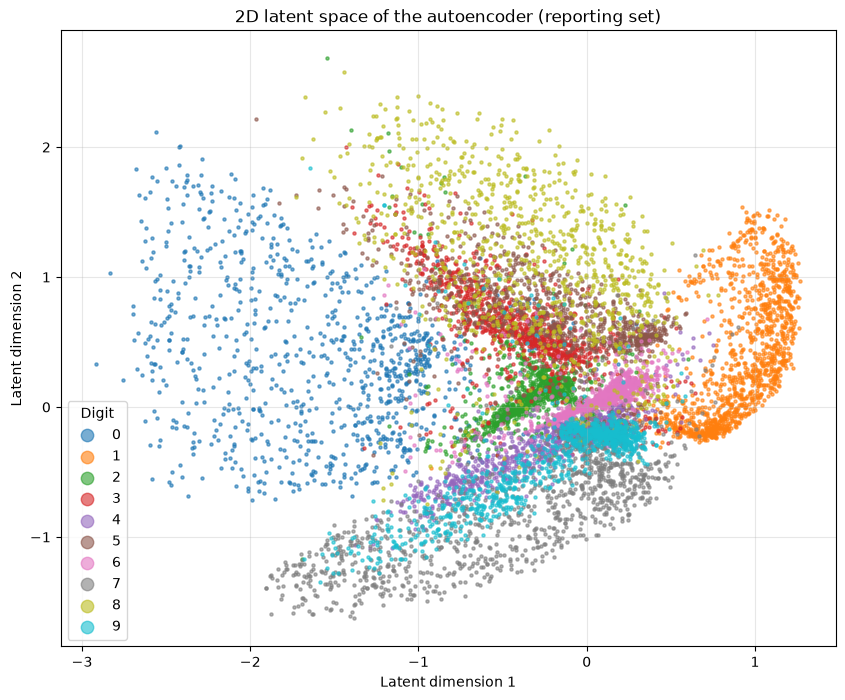

In [67]:
import matplotlib.pyplot as plt

# Check the shape: should be (number of reporting images, 2)
print("Latent features shape:", latents_autoencoder.shape)
print("Labels shape:", labels.shape)

labels = labels.astype(int)  # make sure labels are integers 0-9

plt.figure(figsize=(10, 8))

# Plot each digit separately so it gets its own color and legend entry
for digit in range(10):
    mask = labels == digit
    plt.scatter(
        latents_autoencoder[mask, 0],
        latents_autoencoder[mask, 1],
        s=5,
        alpha=0.6,
        color=plt.cm.tab10(digit),
        label=str(digit)
    )

plt.xlabel("Latent dimension 1")
plt.ylabel("Latent dimension 2")
plt.title("2D latent space of the autoencoder (reporting set)")
plt.legend(title="Digit", markerscale=4)
plt.grid(alpha=0.3)
plt.show()

## 5. Compare with PCA (10 points)

Here you will compare the latent representations learned by your autoencoder with those obtained using a PCA.

1. Apply a PCA to the reporting set (without using the autoencoder) to reduce the data to the same dimensionality as your bottleneck (2 dimensions). Obviously, first use the rest of the data to learn these two components.
2. Visualize the reduced 2D data as a scatterplot, coloring each point by its corresponding digit label.
3. Compare the structure of the two plots (Autoencoder vs. PCA) and briefly discuss the differences (if any) you observe.

In [ ]:
# USE AS MANY CELLS AS NEEDED

## 6. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE